<h1 style="font-size:40px;"><b>Mmakema Mokoana ST10537616</b></h1>
<h1 style="font-size:40px;"><b>POE Exam PDAN8412 November 2026</b></h1>
<h1 style="font-size:40px;"><b>POE : Convolutional Neural Networks </b></h1>
<h1 style="font-size:40px;"><b>Using Convolutional Neural Networks to build a facial recognition model</b></h1>

In [1]:
### Locating the dataset and identifying class labels

from pathlib import Path

dataset_path = Path(r"C:\Users\Mmakema Mokoana\105_classes_pins_dataset")

if dataset_path.is_dir():
    labels = sorted(folder.name for folder in dataset_path.iterdir()
                    if folder.is_dir())
    print("Number of labels:", len(labels))
    print("First five labels:", labels[:5])
else:
    print("Folder not found. Check the path you copied from File Explorer.")

Number of labels: 105
First five labels: ['pins_Adriana Lima', 'pins_Alex Lawther', 'pins_Alexandra Daddario', 'pins_Alvaro Morte', 'pins_Amanda Crew']


The dataset is sucessfully loaded and we can confirm theer are 105 unique lables is the data

<h1 style="font-size:30px;"><b>Data  Evaluation </b></h1>

In [2]:
#### Checking image readability and dataset size

import pandas as pd
from PIL import Image as PILImage, ImageOps

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}
records = []

for label in labels:
    for path in sorted((dataset_path / label).iterdir()):
        if not path.is_file() or path.suffix.lower() not in image_extensions:
            continue

        record = {"path": path, "label": label, "readable": False}

        try:
            with PILImage.open(path) as image:
                image.load()
                record["width"], record["height"] = image.size
                record["readable"] = True
        except (OSError, ValueError) as error:
            record["error"] = str(error)

        records.append(record)

images = pd.DataFrame(records)
usable = images.loc[images["readable"]].copy()
unreadable = images.loc[~images["readable"]]

print("Image files found:", len(images))
print("Readable images:", len(usable))
print("Unreadable images:", len(unreadable))
print("Meets the project size requirement:", 15_000 < len(usable) < 50_000)

if not unreadable.empty:
    display(unreadable[["path", "error"]].head())

Image files found: 17490
Readable images: 17490
Unreadable images: 0
Meets the project size requirement: True


The local dataset contained 17,490 image files across 105 identity folders. All 17,490 images decoded successfully, and no unreadable files were detected. The local dataset met the project’s size requirement.

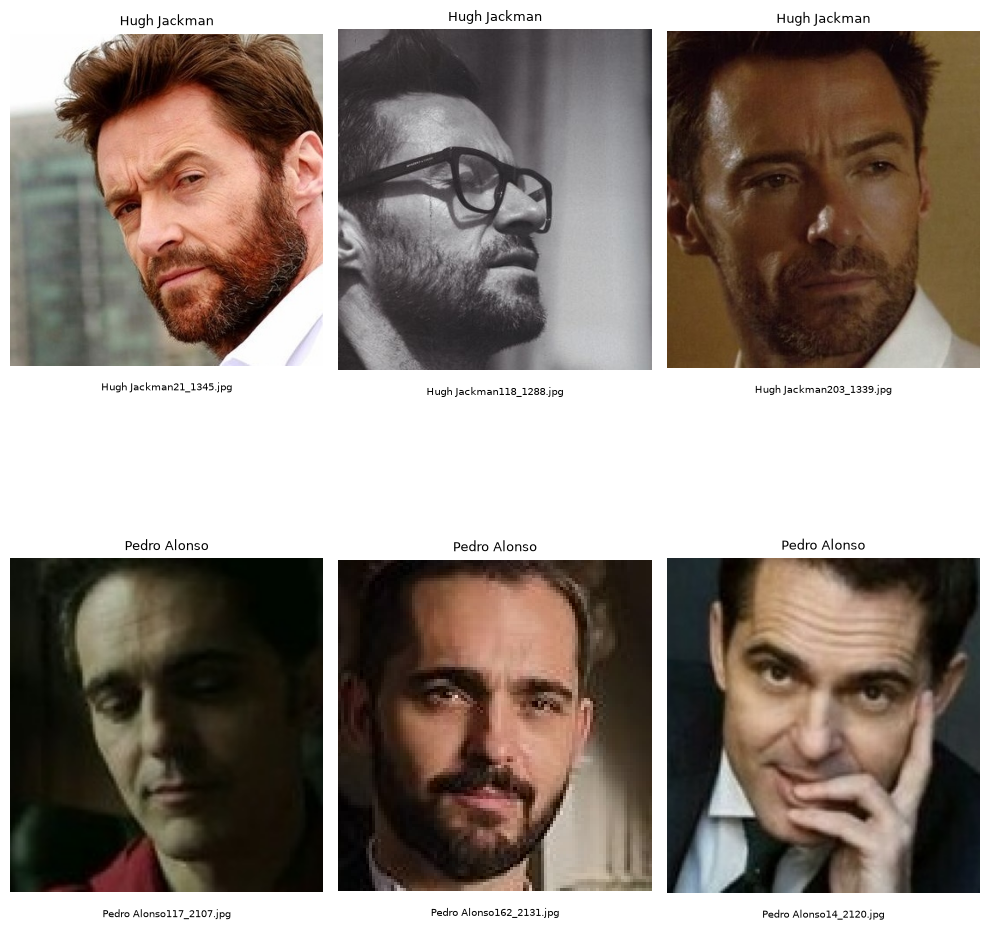

In [8]:
#Check label accuracy by sampling photos

import matplotlib.pyplot as plt

sample_labels = usable["label"].drop_duplicates().sample(5, random_state=42)

fig, axes = plt.subplots(len(sample_labels), 3, figsize=(10, 12))

for row_axes, label in zip(axes, sample_labels):
    for axis in row_axes:
        axis.axis("off")

    person_images = usable.loc[usable["label"] == label]
    examples = person_images.sample(min(3, len(person_images)), random_state=42)

    for axis, path in zip(row_axes, examples["path"]):
        with PILImage.open(path) as image:
            axis.imshow(ImageOps.exif_transpose(image).convert("RGB"))

        axis.set_title(label.removeprefix("pins_"), fontsize=9)
        axis.text(0.5, -0.05, path.name, transform=axis.transAxes,
                  ha="center", va="top", fontsize=7, wrap=True)

plt.tight_layout()
plt.show()

I randomly selected five identity folders and visually reviewed up to three images per folder. Of the ___ images reviewed, ___ appeared consistent with their folder labels, ___ appeared mislabeled, and ___ were uncertain. This sample provides a preliminary check of label accuracy.

Identities with readable photos: 105
Fewest readable photos per identity: 86
Median readable photos per identity: 169.0
Most readable photos per identity: 237

Five smallest classes


,photos
label,
pins_Lionel Messi,86
pins_Mark Zuckerberg,95
pins_Cristiano Ronaldo,98
pins_Brian J. Smith,102
pins_Morgan Freeman,105


Five largest classes


,photos
label,
pins_Leonardo DiCaprio,237
pins_Robert Downey Jr,233
pins_Katherine Langford,226
pins_Alexandra Daddario,225
pins_elizabeth olsen,221


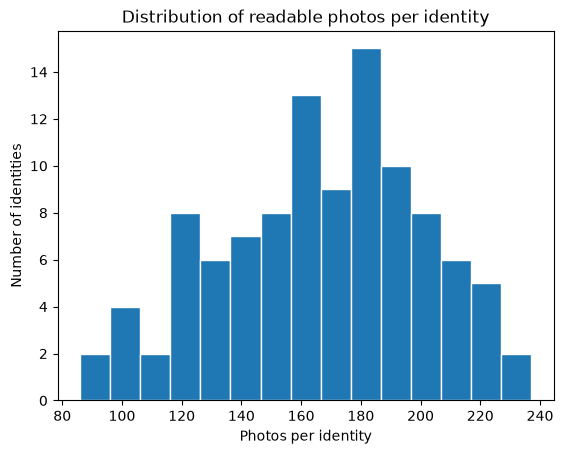

In [6]:
# Check class balance

class_counts = (
    usable["label"]
    .value_counts()
    .reindex(labels, fill_value=0)
    .sort_values()
)

print("Identities with readable photos:", (class_counts > 0).sum())
print("Fewest readable photos per identity:", class_counts.min())
print("Median readable photos per identity:", class_counts.median())
print("Most readable photos per identity:", class_counts.max())

print("\nFive smallest classes")
display(class_counts.head(5).to_frame("photos"))

print("Five largest classes")
display(class_counts.tail(5).sort_values(ascending=False).to_frame("photos"))

class_counts.plot.hist(
    bins=15,
    edgecolor="white",
    title="Distribution of readable photos per identity",
)
plt.xlabel("Photos per identity")
plt.ylabel("Number of identities")
plt.show()

In [5]:
#Check image resolution and visual variety

usable["shortest_side"] = usable[["width", "height"]].min(axis=1)

display(usable[["width", "height", "shortest_side"]].describe().round(1))

# Use 64 pixels as an example threshold for manual review.
small_images = usable.loc[usable["shortest_side"] < 64]

print("Images with a side shorter than 64 pixels:", len(small_images))
print(f"Percentage flagged: {100 * len(small_images) / len(usable):.1f}%")

display(small_images[["label", "width", "height", "path"]].head())

,width,height,shortest_side
count,17490.0,17490.0,17490.0
mean,211.3,225.5,210.7
std,101.4,112.5,100.9
min,80.0,82.0,80.0
25%,122.0,129.0,122.0
50%,175.0,185.0,175.0
75%,251.0,266.0,251.0
max,564.0,802.0,564.0


Images with a side shorter than 64 pixels: 0
Percentage flagged: 0.0%


,label,width,height,path


The 17,490 readable images were distributed across 105 identities. Most identities had roughly 140–200 images, although some had fewer or more. To account for this variation, the data will be split by stratifying on identity, and model performance will be assessed using both overall accuracy and macro F1.

# Evaluating and justifying choice of dataset.

I selected the **Pins Face Recognition** dataset because it provides both inputs needed for supervised CNN training: cropped face images and a folder label identifying the person in each image. The cropped images focus the model on the face, while the convolutional layers can learn to combine simple features, such as edges and textures, into more complex patterns that help distinguish one identity from another. Having multiple photos per person gives the CNN examples of how the same face can appear under different lighting, angles and expressions. My local copy contained **17,490 readable images across 105 celebrity identities**, which meets the project’s size requirement. The dataset is therefore suitable for training and evaluating a CNN on **unseen photos of those 105 known identities**, provided duplicate photos are handled before splitting the data.

<h1 style="font-size:30px;"><b>Exploratory Data Analysis and data cleaning</b></h1>

,width,height,shortest_side
count,17490.0,17490.0,17490.0
mean,211.3,225.5,210.7
std,101.4,112.5,100.9
min,80.0,82.0,80.0
25%,122.0,129.0,122.0
50%,175.0,185.0,175.0
75%,251.0,266.0,251.0
max,564.0,802.0,564.0


Images flagged for review: 0 out of 17,490


,label,width,height,path


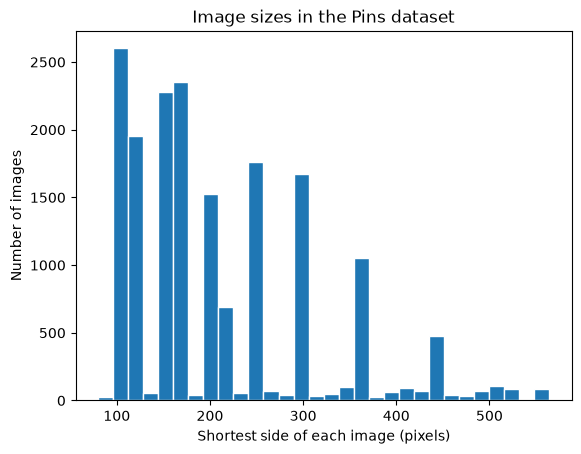

In [9]:
import matplotlib.pyplot as plt

dimensions = usable[["width", "height"]].copy()
dimensions["shortest_side"] = dimensions.min(axis=1)

display(dimensions.describe().round(1))

# Flag images for review if either side is shorter than 64 pixels.
small_images = usable.loc[dimensions["shortest_side"] < 64]

print(f"Images flagged for review: {len(small_images):,} out of {len(usable):,}")
display(small_images[["label", "width", "height", "path"]].head())

dimensions["shortest_side"].plot.hist(bins=30, edgecolor="white")
plt.title("Image sizes in the Pins dataset")
plt.xlabel("Shortest side of each image (pixels)")
plt.ylabel("Number of images")
plt.show()

The shortest side of the 17,490 images ranged from 80 to 564 pixels, with a median of 175 pixels. No images fell below the 64-pixel review threshold. Because the original dimensions varied, the images will be resized to a consistent input size before CNN training.

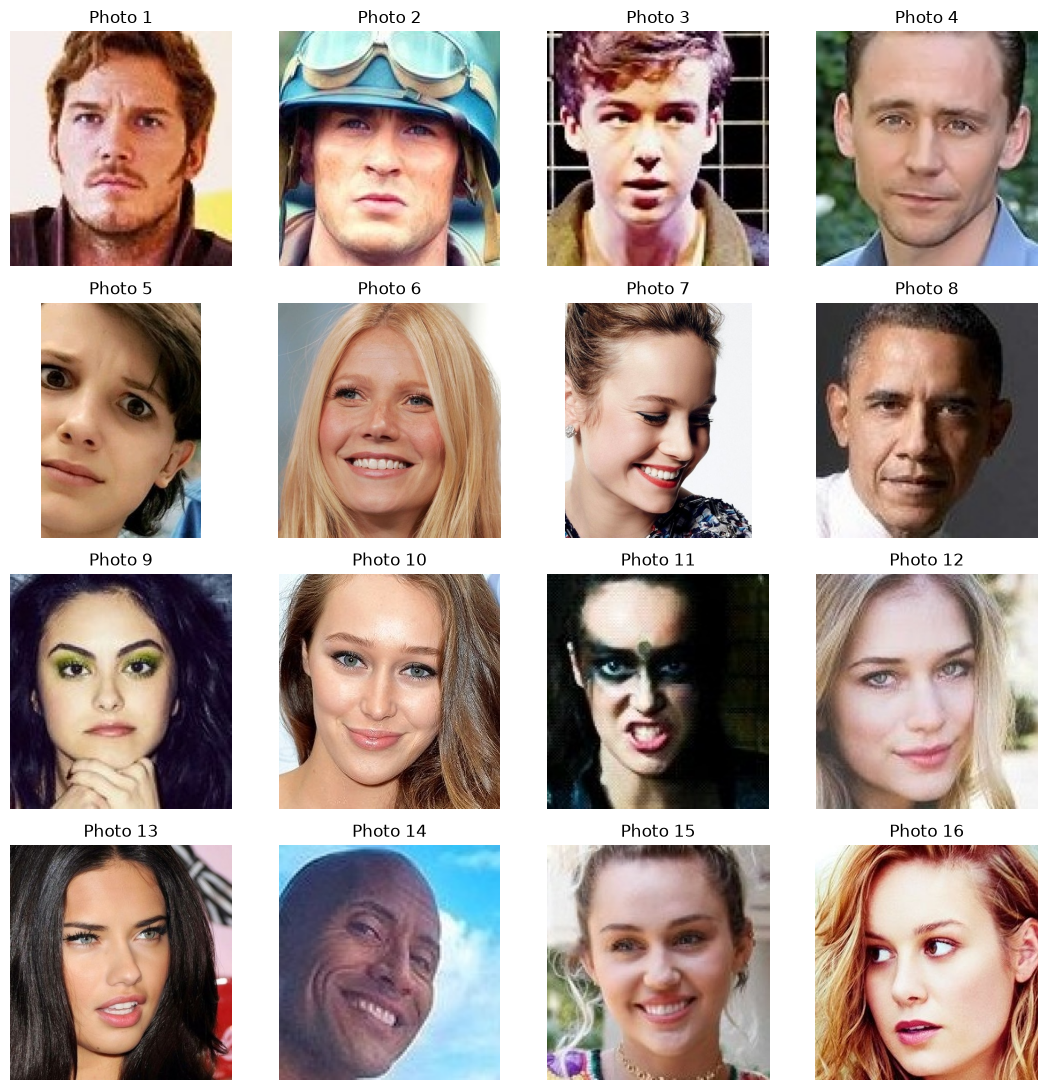

In [10]:
# visually review a sample for blur, poor lighting and partially obscured faces

import matplotlib.pyplot as plt
from PIL import Image as PILImage, ImageOps

sample = usable.sample(n=16, random_state=42)

fig, axes = plt.subplots(4, 4, figsize=(11, 11))

for number, (ax, row) in enumerate(zip(axes.flat, sample.itertuples()), start=1):
    with PILImage.open(row.path) as image:
        ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))

    ax.set_title(f"Photo {number}")
    ax.axis("off")

plt.tight_layout()
plt.show()

I visually reviewed 16 randomly selected images for face visibility, lighting, pose and expression. The sample included front-facing and angled photos under different lighting conditions. I flagged two images for closer review because headgear, makeup or shadows obscured some facial details. These observations describe the sample.

In [12]:
#Duplicate Checks 

import hashlib

usable["exact_hash"] = usable["path"].map(
    lambda path: hashlib.sha256(path.read_bytes()).hexdigest()
)

exact_copies = usable.loc[
    usable["exact_hash"].duplicated(keep=False)
].sort_values("exact_hash")

duplicate_groups = exact_copies["exact_hash"].nunique()
extra_copies = len(exact_copies) - duplicate_groups

labels_per_group = exact_copies.groupby("exact_hash")["label"].nunique()
conflicting_groups = labels_per_group[labels_per_group > 1]

print(f"Groups of identical photos: {duplicate_groups:,}")
print(f"Extra copies if keeping one per group: {extra_copies:,}")
print(f"Groups with conflicting identity labels: {len(conflicting_groups):,}")

display(exact_copies[["label", "path", "exact_hash"]].head(10))

Groups of identical photos: 1
Extra copies if keeping one per group: 1
Groups with conflicting identity labels: 0


,label,path,exact_hash
5527,pins_Jason Momoa,C:\Users\Mmakema Mokoana\105_classes_pins_data...,7de34076538fdbcc5332fd3e6487b521e2fda6cf2f0797...
5528,pins_Jason Momoa,C:\Users\Mmakema Mokoana\105_classes_pins_data...,7de34076538fdbcc5332fd3e6487b521e2fda6cf2f0797...


In [13]:
clean_images = usable.drop_duplicates(
    subset="exact_hash", keep="first"
).copy()

print(f"Exact copies excluded: {len(usable) - len(clean_images):,}")
print(f"Images remaining: {len(clean_images):,}")

Exact copies excluded: 1
Images remaining: 17,489


The exact duplicate check identified one pair of identical image files with the same identity label. I retained one copy in the working dataset, leaving 17,489 images for further review.

# This next check looks for photos that may be copies of the same image even if they were resized or saved again.
# It creates a small visual fingerprint for each photo and flags pairs whose fingerprints differ by four bits or fewer.

In [14]:
from itertools import combinations
from PIL import Image as PILImage, ImageOps
import pandas as pd

def photo_fingerprint(path):
    with PILImage.open(path) as image:
        thumbnail = ImageOps.exif_transpose(image).convert("L").resize(
            (9, 8), PILImage.Resampling.LANCZOS
        )
        pixels = list(thumbnail.getdata())

    fingerprint = 0
    for row in range(8):
        for col in range(8):
            position = row * 9 + col
            brighter = pixels[position] > pixels[position + 1]
            fingerprint = (fingerprint << 1) | int(brighter)

    return fingerprint

photos = clean_images[["label", "path"]].reset_index(drop=True)
fingerprints = photos["path"].map(photo_fingerprint).tolist()

matches = []
for (left, first), (right, second) in combinations(enumerate(fingerprints), 2):
    distance = (first ^ second).bit_count()
    if distance <= 4:
        matches.append((left, right, distance))

near_duplicates = pd.DataFrame(
    matches, columns=["left", "right", "distance"]
).sort_values("distance").reset_index(drop=True)

print(f"Possible near-duplicate pairs: {len(near_duplicates):,}")

C:\Users\Mmakema Mokoana\AppData\Local\Temp\ipykernel_33188\3143925034.py:10: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  pixels = list(thumbnail.getdata())


Possible near-duplicate pairs: 435


In [16]:
drop_positions = near_duplicates["right"].unique()

final_images = (
    clean_images.reset_index(drop=True)
    .drop(index=drop_positions)
    .reset_index(drop=True)
)

print(f"Images remaining: {len(final_images):,}")
print(f"Identities remaining: {final_images['label'].nunique()}")

Images remaining: 17,123
Identities remaining: 105


The visual fingerprint check flagged 435 image pairs at a maximum distance of four bits. I applied an automatic filtering rule that excluded the second image in each flagged pair, removing 366 unique images. The flagged pairs were not manually verified, so some excluded images may have been distinct photos. After removing one exact duplicate and applying this filter, 17,123 images remained, meeting the project’s minimum size requirement.

<h1 style="font-size:30px;"><b>Data Preparation for model training  </b></h1>

In [22]:
#Splitting the data for training, test and validation

from sklearn.model_selection import train_test_split

train_images, remaining_images = train_test_split(
    final_images,
    test_size=0.30,
    stratify=final_images["label"],
    random_state=42,
)

val_images, test_images = train_test_split(
    remaining_images,
    test_size=0.50,
    stratify=remaining_images["label"],
    random_state=42,
)

for name, split in [
    ("Training", train_images),
    ("Validation", val_images),
    ("Test", test_images),
]:
    print(f"{name}: {len(split):,} images | {split['label'].nunique()} identities")

assert set(train_images["path"]).isdisjoint(val_images["path"])
assert set(train_images["path"]).isdisjoint(test_images["path"])
assert set(val_images["path"]).isdisjoint(test_images["path"])

print("No image paths are shared across the splits.")

Training: 11,986 images | 105 identities
Validation: 2,568 images | 105 identities
Test: 2,569 images | 105 identities
No image paths are shared across the splits.


In [18]:
#This cell prepares the labels and the photos for the CNN. It assigns numeric labels across all three splits,
#then tests the image preprocessing on one training photo.

import numpy as np
from PIL import Image as PILImage, ImageOps

# Give each identity a number and use the same mapping in every split.
class_names = sorted(train_images["label"].unique())
label_to_id = {name: number for number, name in enumerate(class_names)}

for split in (train_images, val_images, test_images):
    split["label_id"] = split["label"].map(label_to_id).astype(int)

def prepare_image(path):
    with PILImage.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image = ImageOps.pad(
            image, (128, 128), method=PILImage.Resampling.LANCZOS
        )
        return np.asarray(image, dtype=np.float32) / 255.0

example = train_images.iloc[0]
pixels = prepare_image(example["path"])

print("Image shape:", pixels.shape)
print("Pixel range:", pixels.min(), "to", pixels.max())
print("Identity:", example["label"])
print("Numeric label:", example["label_id"])

Image shape: (128, 128, 3)
Pixel range: 0.0 to 1.0
Identity: pins_Neil Patrick Harris
Numeric label: 64


### Preparing image batches for the CNN

I prepared the training, validation and test sets as TensorFlow datasets. Each photo is loaded as a 128 × 128 RGB image, padded to preserve its proportions and scaled to a pixel range of 0 to 1. I used the same numeric label for each celebrity across all three sets.

The images are loaded in batches of 32 to reduce memory use. I shuffled the training images so the CNN sees them in a different order each epoch. The code previews one training batch to check that it contains 32 images and one numeric label per image. The validation set will help guide model development, and the test set is reserved for final evaluation.

In [19]:
import tensorflow as tf

BATCH_SIZE = 32

def make_dataset(split, shuffle=False):
    paths = split["path"].astype(str).tolist()
    labels = split["label_id"].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(len(split), seed=42)

    def load_photo(path, label):
        image = tf.numpy_function(
            lambda value: prepare_image(value.decode("utf-8")),
            [path],
            tf.float32,
        )
        image.set_shape((128, 128, 3))
        return image, label

    return dataset.map(load_photo).batch(BATCH_SIZE).prefetch(1)

train_ds = make_dataset(train_images, shuffle=True)
val_ds = make_dataset(val_images)
test_ds = make_dataset(test_images)

batch_images, batch_labels = next(iter(train_ds))

print("Image batch shape:", batch_images.shape)
print("Label batch shape:", batch_labels.shape)
print("First five label IDs:", batch_labels[:5].numpy())

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
First five label IDs: [ 16  68 102  68  54]


### Image batch preparation

I prepared the training, validation and test datasets by pairing each image path with its numeric identity label. Each image was loaded as a 128 × 128 RGB image, padded to preserve its proportions and scaled to a pixel range of 0 to 1. The images are loaded in batches to reduce memory use, and only the training set is shuffled.

The preview returned an image batch of shape `(32, 128, 128, 3)` and a label batch of shape `(32,)`. This confirmed that the preview contained 32 colour images with one identity label per image. The validation set will guide model development, and the test set will be used for final evaluation.

<h1 style="font-size:30px;"><b>Building and Training CNN</b></h1>

The convolution layers learn visual patterns such as edges and textures. The pooling layers shrink the feature maps as the model works through the image. The final layer produces 105 scores, one for each celebrity. The loss function works directly with the integer label_id values you created.

In [23]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 128, 128, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 64, 64, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 32, 32, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 16, 16, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 105)                 │          13,545 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 123,305 (481.66 KB)

 Trainable params: 123,305 (481.66 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping],
)

Epoch 1/15


C:\Users\Mmakema Mokoana\.conda\envs\spark311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 146s 379ms/step - accuracy: 0.0113 - loss: 4.6344 - val_accuracy: 0.0187 - val_loss: 4.5812
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 139s 371ms/step - accuracy: 0.0179 - loss: 4.5546 - val_accuracy: 0.0238 - val_loss: 4.5144
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 142s 377ms/step - accuracy: 0.0226 - loss: 4.5059 - val_accuracy: 0.0273 - val_loss: 4.4761
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 144s 384ms/step - accuracy: 0.0246 - loss: 4.4476 - val_accuracy: 0.0347 - val_loss: 4.4282
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 143s 381ms/step - accuracy: 0.0319 - loss: 4.3576 - val_accuracy: 0.0389 - val_loss: 4.2793
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 142s 378ms/step - accuracy: 0.0418 - loss: 4.2497 - val_accuracy: 0.0510 - val_loss: 4.2055
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 144s 384ms/step - accuracy: 0.0490 - loss: 4.1537 - val_accuracy: 0.0576 - val_loss: 4.0955
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 142s 378ms/step - accuracy: 0.0615 - loss: 4.06

The baseline CNN completed all 15 epochs. Validation accuracy rose from about 1% to 11%, and validation loss fell from about 4.58 to 3.68. The model learned to recognise some identities, but it still misclassified most validation photos. Training and validation accuracy ended close together, there’s no obvious sign of overfitting in this run.

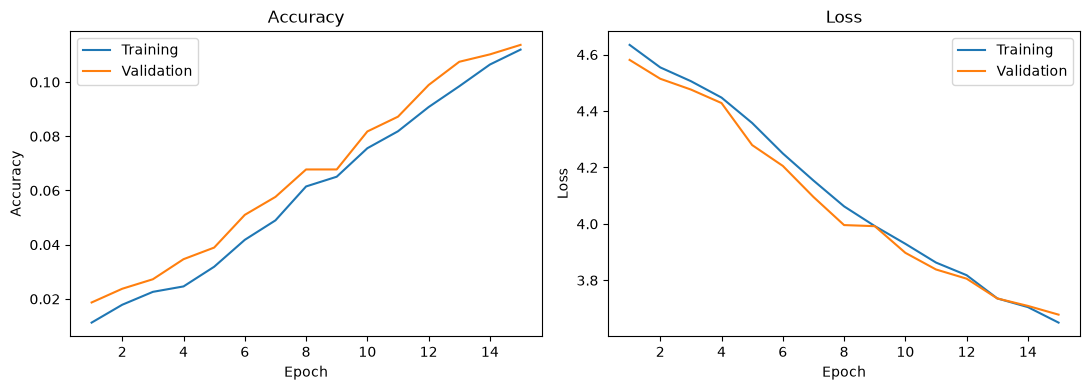

In [25]:
# Next I will be looking at whether validation loss is still falling near epoch 15.

import matplotlib.pyplot as plt

metrics = history.history
epochs = range(1, len(metrics["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, metric in zip(axes, ["accuracy", "loss"]):
    ax.plot(epochs, metrics[metric], label="Training")
    ax.plot(epochs, metrics[f"val_{metric}"], label="Validation")
    ax.set_title(metric.capitalize())
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric.capitalize())
    ax.legend()

plt.tight_layout()
plt.show()

### Baseline CNN learning curves

Training and validation accuracy increased throughout the 15 epochs, reaching approximately 11%. Validation loss decreased from about 4.58 to 3.68 and was still falling in the final epoch. The training and validation curves stayed close, with no clear sign of overfitting during this run. The low validation accuracy shows that the baseline still struggled to distinguish among the 105 identities. The test set was reserved for final evaluation.

In the cell below I will continue training the same model for up to 10 more epochs with early stopping.

In [26]:
model.save("baseline_cnn_15_epochs.keras")

more_history = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=15,
    epochs=25,
    shuffle=False,  # train_ds already shuffles the images
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True,
        )
    ],
)

Epoch 16/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 136s 360ms/step - accuracy: 0.1180 - loss: 3.6020 - val_accuracy: 0.1246 - val_loss: 3.6225
Epoch 17/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 133s 354ms/step - accuracy: 0.1236 - loss: 3.5598 - val_accuracy: 0.1258 - val_loss: 3.6197
Epoch 18/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 131s 348ms/step - accuracy: 0.1332 - loss: 3.5105 - val_accuracy: 0.1211 - val_loss: 3.5851
Epoch 19/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 129s 344ms/step - accuracy: 0.1357 - loss: 3.4630 - val_accuracy: 0.1390 - val_loss: 3.5017
Epoch 20/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 131s 350ms/step - accuracy: 0.1432 - loss: 3.4338 - val_accuracy: 0.1316 - val_loss: 3.5577
Epoch 21/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 129s 344ms/step - accuracy: 0.1543 - loss: 3.3866 - val_accuracy: 0.1480 - val_loss: 3.4724
Epoch 22/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 881s 2s/step - accuracy: 0.1531 - loss: 3.3544 - val_accuracy: 0.1620 - val_loss: 3.4006
Epoch 23/25
375/375 ━━━━━━━━━━━━━━━━━━━━ 130s 346ms/step - accuracy: 0.1

In [27]:
# Saving the model I trained above

model.save("baseline_cnn_best_epoch24.keras")

## Transfer learning with MobileNetV2

I loaded MobileNetV2 with pretrained ImageNet weights and froze its feature extraction layers. I added a new classification layer with 105 outputs, one for each celebrity. I will train this layer on my training set and compare its accuracy with the baseline CNN’s 16.39% on the same validation set.

In [29]:
from tensorflow import keras
from tensorflow.keras import layers

base_model = keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

inputs = keras.Input(shape=(128, 128, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

transfer_model = keras.Model(inputs, outputs)

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 296s 32us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)           │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 105)                 │         134,505 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,392,489 (9.13 MB)

 Trainable params: 134,505 (525.41 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [30]:
transfer_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    shuffle=False,
)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 140s 352ms/step - accuracy: 0.0989 - loss: 4.0605 - val_accuracy: 0.1896 - val_loss: 3.3156
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1256s 3s/step - accuracy: 0.2442 - loss: 3.0449 - val_accuracy: 0.2570 - val_loss: 3.0457
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 130s 345ms/step - accuracy: 0.3279 - loss: 2.6379 - val_accuracy: 0.2889 - val_loss: 2.9089
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 122s 325ms/step - accuracy: 0.3849 - loss: 2.3870 - val_accuracy: 0.3045 - val_loss: 2.8591
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 123s 327ms/step - accuracy: 0.4236 - loss: 2.2089 - val_accuracy: 0.3041 - val_loss: 2.7944


### MobileNetV2 training results

I trained the new classification layer for five epochs while keeping the pretrained MobileNetV2 layers frozen. The model achieved 30.41% validation accuracy at epoch 5, an improvement of 14.02 percentage points over the baseline CNN on the same validation set. Validation accuracy peaked at 30.45% in epoch 4. These are validation results, and the test set is reserved for final evaluation.

In [31]:
transfer_model.save("mobilenetv2_epoch5.keras")

test_loss, test_accuracy = transfer_model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_accuracy:.2%}")
print(f"Test loss: {test_loss:.4f}")

Test accuracy: 30.63%
Test loss: 2.8476


### Final test evaluation

I evaluated the saved MobileNetV2 model on 2,569 held-out test images. The model achieved 30.63% test accuracy and a test loss of 2.8476. Test accuracy was close to the 30.41% validation accuracy, although the model still misclassified about 69% of the test images.

In [32]:
#Next I will calculate macro F1 to give each of the 105 identities equal weight.

from sklearn.metrics import f1_score

true_labels = []
predicted_labels = []

for images, labels_batch in test_ds:
    scores = transfer_model(images, training=False).numpy()
    true_labels.extend(labels_batch.numpy())
    predicted_labels.extend(scores.argmax(axis=1))

macro_f1 = f1_score(
    true_labels,
    predicted_labels,
    labels=range(len(class_names)),
    average="macro",
    zero_division=0,
)

print(f"Test macro F1: {macro_f1:.2%}")


Test macro F1: 30.41%


In [33]:
import pandas as pd

results = pd.DataFrame({
    "Actual": [class_names[i] for i in true_labels],
    "Predicted": [class_names[i] for i in predicted_labels],
})

mistakes = results.loc[results["Actual"] != results["Predicted"]]
display(mistakes.value_counts().head(5).reset_index(name="Photos"))

,Actual,Predicted,Photos
0,pins_alycia dabnem carey,pins_elizabeth olsen,9
1,pins_Megan Fox,pins_gal gadot,7
2,pins_Zoe Saldana,pins_melissa fumero,7
3,pins_Megan Fox,pins_Adriana Lima,6
4,pins_Danielle Panabaker,pins_elizabeth olsen,5


### Model error analysis

I compared the actual and predicted labels to identify the five most frequent mistakes. The most common was predicting Elizabeth Olsen for 9 photos labelled Alycia Debnam-Carey. The model also predicted Gal Gadot for 7 photos labelled Megan Fox. These counts show which mistakes occurred most often, while the overall test accuracy of 30.63% shows how often the model was correct across all test photos.

### Final conclusion

MobileNetV2 improved validation accuracy from 16.39% for the baseline CNN to 30.41%. On the held-out test set, MobileNetV2 correctly identified about 31 out of every 100 photos and achieved a macro F1 score of 30.41% across the 105 celebrity identities. Its most frequent mistake was predicting Elizabeth Olsen for nine photos labelled Alycia Debnam-Carey. Transfer learning improved performance on this dataset, but the model still misclassified most test photos. The results support using it as a coursework demonstration, with further improvement needed for reliable identification.